In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sympy import symbols, lambdify, sin, exp

from IPython.display import display

import time

# Utility functions

In [2]:
def do_poly_reg(X_train, X_test, y_train, y_test, degree):
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    lr = LinearRegression()
    lr.fit(X_train_poly, y_train)
    
    mse_train = round(mean_squared_error(y_train, lr.predict(X_train_poly)), 2)
    mse_test = round(mean_squared_error(y_test, lr.predict(X_test_poly)), 2)

    y_pred_train = lr.predict(X_train_poly)
    y_pred_test = lr.predict(X_test_poly)
    r2_train = round(r2_score(y_train, y_pred_train), 2)
    r2_test = round(r2_score(y_test, y_pred_test), 2)
    
    return lr.coef_.flatten(), lr.intercept_[0], mse_train, mse_test, r2_train, r2_test

# Demo 1:

## Defining a population

,X,y
14,-4.307367,55.897231
122,4.279204,0.663830
426,8.537038,31.302272
927,-2.356345,30.586270
803,-0.897556,17.777706


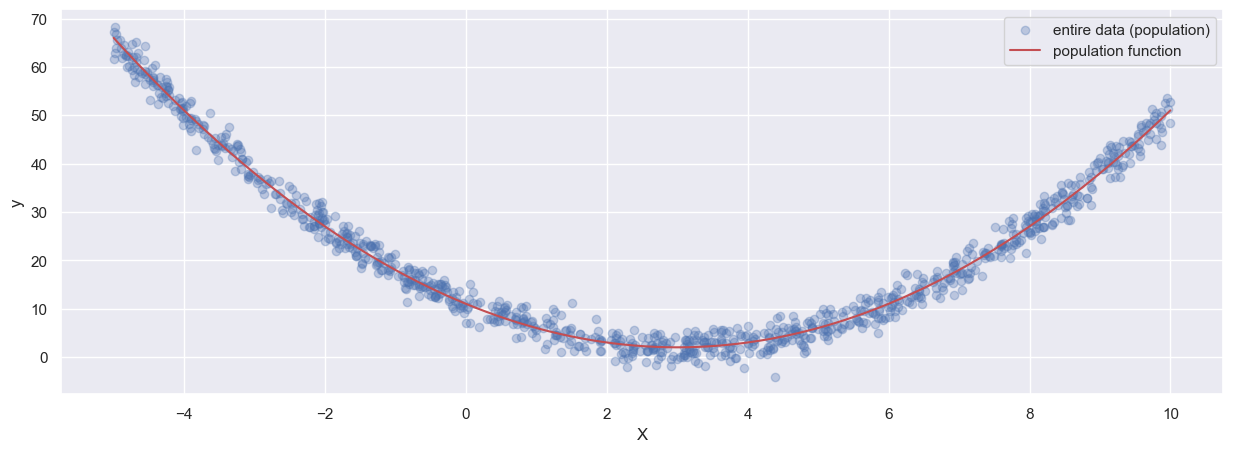

In [3]:
x = np.linspace(-5, 10, 1000)
# population_fun = np.sin(2*(np.pi* x))

x_symbol = symbols("x")
population_fun = (x_symbol-3)**2 + 2
population_fun_ = lambdify(x_symbol, population_fun)

N = 1000
sigma = 2
x_data = np.random.uniform(x.min(), x.max(), size=N)
y_data = ((x_data-3)**2 + 2) + np.random.normal(scale=sigma, size=N)

df_pop = pd.DataFrame(data=np.column_stack((x_data, y_data)), columns=["X", "y"])
display(df_pop.sample(5))
X, y = df_pop[["X"]].values, df_pop[["y"]].values


plt.figure(figsize=(15, 5))

plt.scatter(X, y, label="entire data (population)", alpha=0.3)
plt.plot(x, population_fun_(x), "r", label="population function")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## Underfitting vs overfitting

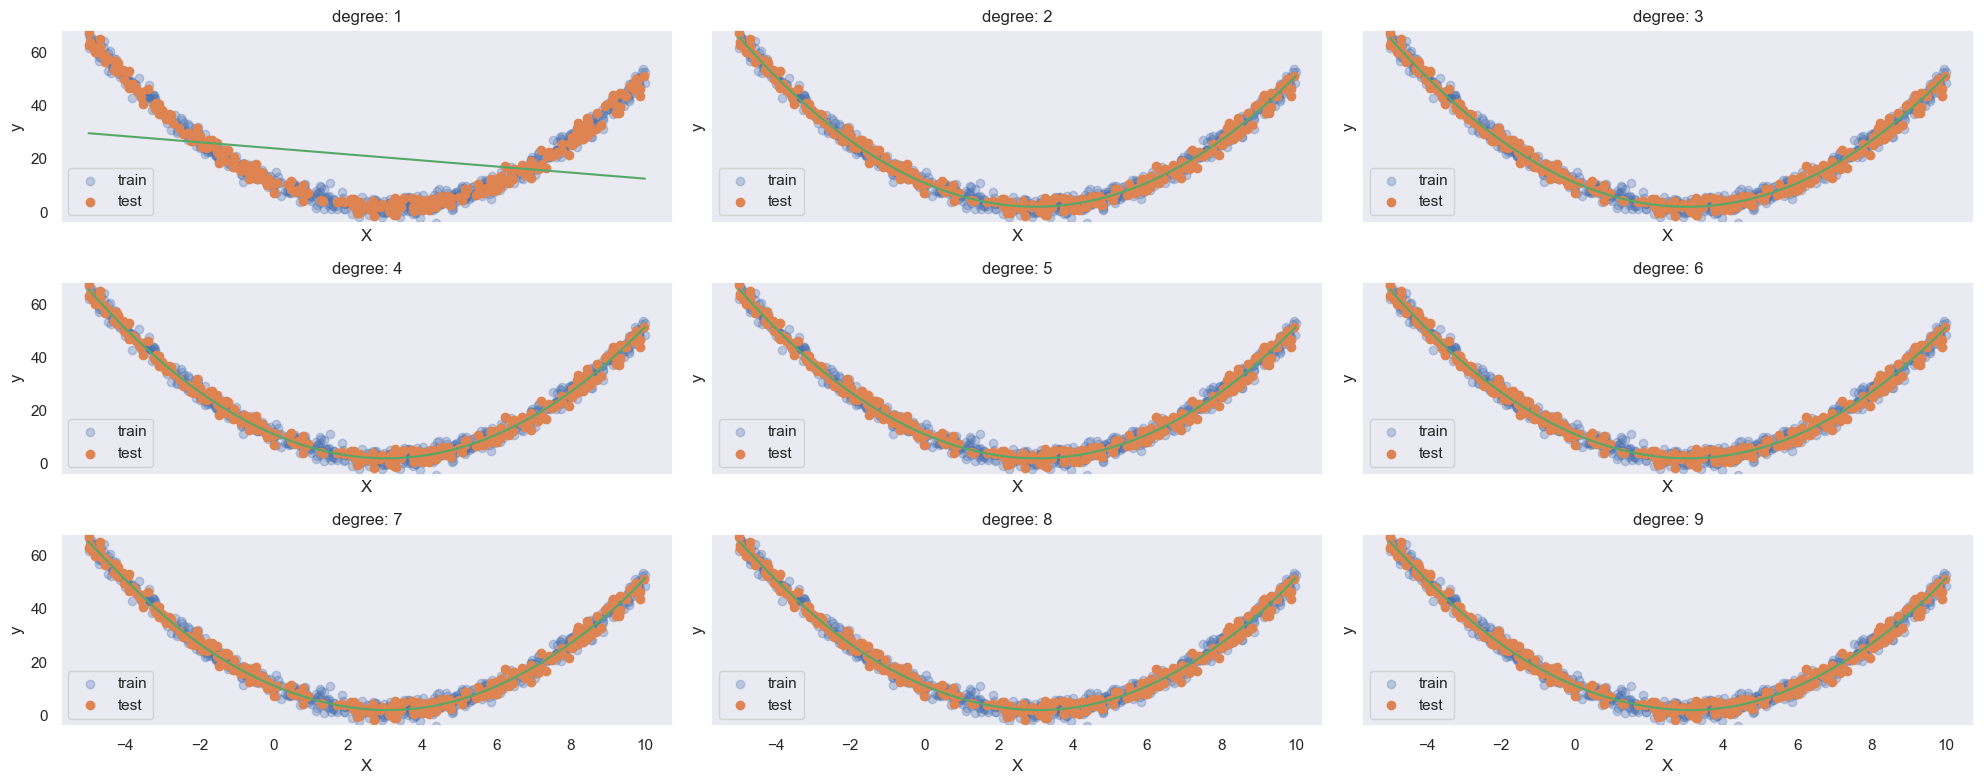

In [5]:
x_ = np.linspace(X.min(), X.max())
# degrees = [2, 3, 5, 10, 15, 20, 30, 40, 50]

degrees = list(range(1, 10))
train_mses, test_mses, train_r2s, test_r2s = [], [], [], []
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(20, 8), sharex=True, sharey=True)
ax = ax.flatten()
for i, degree in enumerate(degrees):
    w, b, mse_train, mse_test, r2_train, r2_test = do_poly_reg(X_train, X_test, y_train, y_test, degree)
    train_mses.append(mse_train)
    test_mses.append(mse_test)
    train_r2s.append(r2_train)
    test_r2s.append(r2_test)
    
    y_hat = lambda x, w, b: sum([w[i]*x**i for i in range(len(w))]) + b
    ax[i].scatter(X_train, y_train, label="train", alpha=0.3)
    ax[i].scatter(X_test, y_test, label="test")
    ax[i].plot(x_, y_hat(x_, w, b), color="g")
    ax[i].grid()
    ax[i].set_ylim([y.min(), y.max()])
    ax[i].set_title(f"degree: {degree}")
    ax[i].legend()
    ax[i].set_xlabel("X")
    ax[i].set_ylabel("y")
plt.tight_layout()

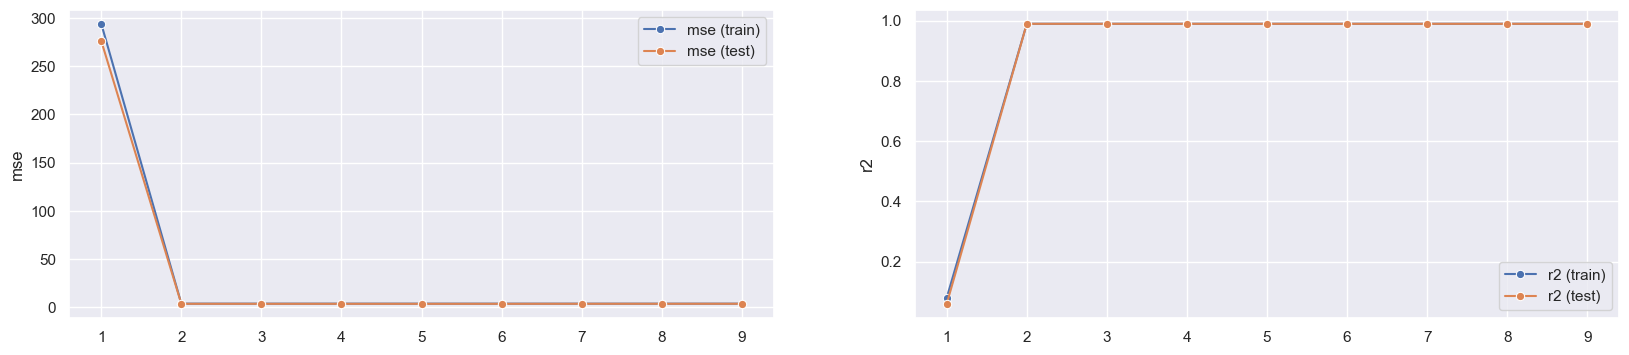

In [6]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 4))
sns.lineplot(x=degrees, y=train_mses, marker="o", label="mse (train)", ax=ax[0])
sns.lineplot(x=degrees, y=test_mses, marker="o", label="mse (test)", ax=ax[0])
ax[0].set_xticks(degrees, degrees)
ax[0].set_ylabel("mse")

sns.lineplot(x=degrees, y=train_r2s, marker="o", label="r2 (train)", ax=ax[1])
sns.lineplot(x=degrees, y=test_r2s, marker="o", label="r2 (test)", ax=ax[1])
ax[1].set_xticks(degrees, degrees)
ax[1].set_ylabel("r2")
plt.legend()

# Demo 2:

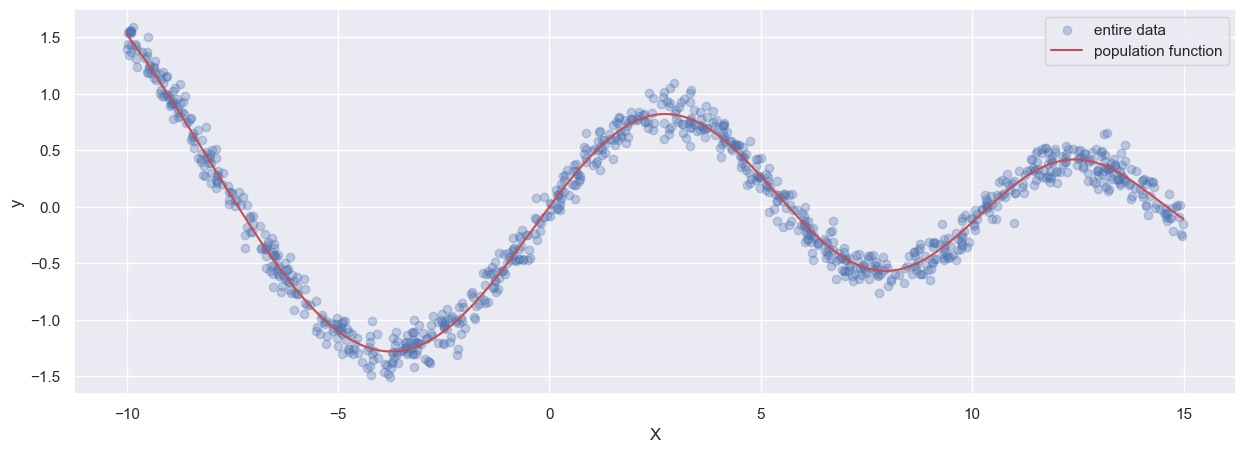

In [14]:
x_symbol = symbols("x")
population_fun = sin(0.01*x_symbol**2 + 0.5*x_symbol)*exp(-0.07*x_symbol)
population_fun_ = lambdify(x_symbol, population_fun)



x = np.linspace(-10, 15, 1000)


N = 1000
sigma = 0.1
x_data = np.random.uniform(x.min(), x.max(), size=N)
y_data = np.sin(0.01*x_data**2 + 0.5*x_data)*np.exp(-0.07*x_data) + np.random.normal(scale=sigma, size=N)

df_pop = pd.DataFrame(data=np.column_stack((x_data, y_data)), columns=["X", "y"])
X, y = df_pop[["X"]].values, df_pop[["y"]].values


plt.figure(figsize=(15, 5))
plt.scatter(X, y, label="entire data", alpha=0.3)
plt.plot(x, population_fun_(x), "r", label="population function")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()

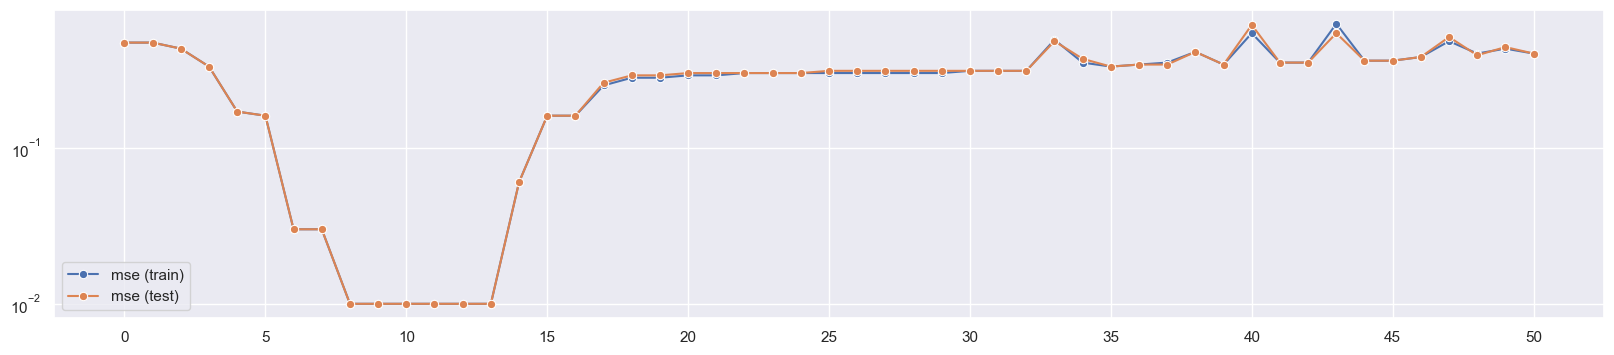

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

x_ = np.linspace(X.min(), X.max())

degrees = list(range(51))
train_mses, test_mses, train_r2s, test_r2s = [], [], [], []

for i, degree in enumerate(degrees):
    w, b, mse_train, mse_test, r2_train, r2_test = do_poly_reg(X_train, X_test, y_train, y_test, degree)
    train_mses.append(mse_train)
    test_mses.append(mse_test)
    train_r2s.append(r2_train)
    test_r2s.append(r2_test)

plt.figure(figsize=(20, 4))
sns.lineplot(x=degrees, y=train_mses, marker="o", label="mse (train)")
sns.lineplot(x=degrees, y=test_mses, marker="o", label="mse (test)")
plt.xticks(degrees[::5], degrees[::5])
plt.yscale("log")
plt.legend()

## estimating the function

In [16]:
y_hat = lambda x, w, b: sum([w[i]*x**i for i in range(len(w))]) + b

start = time.time()

degrees = list(range(15))
N_expt = 500
train_mses, test_mses, train_r2s, test_r2s = np.zeros((len(degrees), N_expt)), np.zeros((len(degrees), N_expt)), np.zeros((len(degrees), N_expt)), np.zeros((len(degrees), N_expt))
bias2, variance = np.zeros(len(degrees)), np.zeros(len(degrees))


x_ = np.linspace(X.min(), X.max())

for i, degree in enumerate(degrees):
    fun_hat = np.zeros((N_expt, len(x_)))
    for j in range(N_expt):
        df_sample = df_pop.sample(100)
        X, y = df_sample[["X"]].values, df_sample[["y"]].values
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=np.random.randint(low=20, high=100))
        w, b, mse_train, mse_test, r2_train, r2_test = do_poly_reg(X_train, X_test, y_train, y_test, degree)
        train_mses[i, j] = mse_train
        test_mses[i, j] = mse_test
        train_r2s[i, j] = r2_train
        test_r2s[i, j] = r2_test
        fun_hat[j, :] = y_hat(x_, w, b)
    bias2_ = ((fun_hat.mean(axis=0) - population_fun_(x_))**2).mean()
    variance_ = ((fun_hat - fun_hat.mean(axis=0))**2).mean()
    bias2[i] = bias2_
    variance[i] = variance_

end = time.time()
print(f"Finished in {end-start} seconds...")



# plt.figure(figsize=(20, 4))
# plt.plot(degrees, train_mses.mean(axis=1), label=r"$\overline{MSE}_{train}$")
# plt.plot(degrees, test_mses.mean(axis=1), label=r"$\overline{MSE}_{test}$")
# plt.xticks(degrees[::5], degrees[::5])
# plt.xlabel("Model Complexity [degrees]")
# plt.ylabel("Error")
# plt.legend()
# plt.yscale("log")

Finished in 127.43391609191895 seconds...


### bias variance tradeoff curve

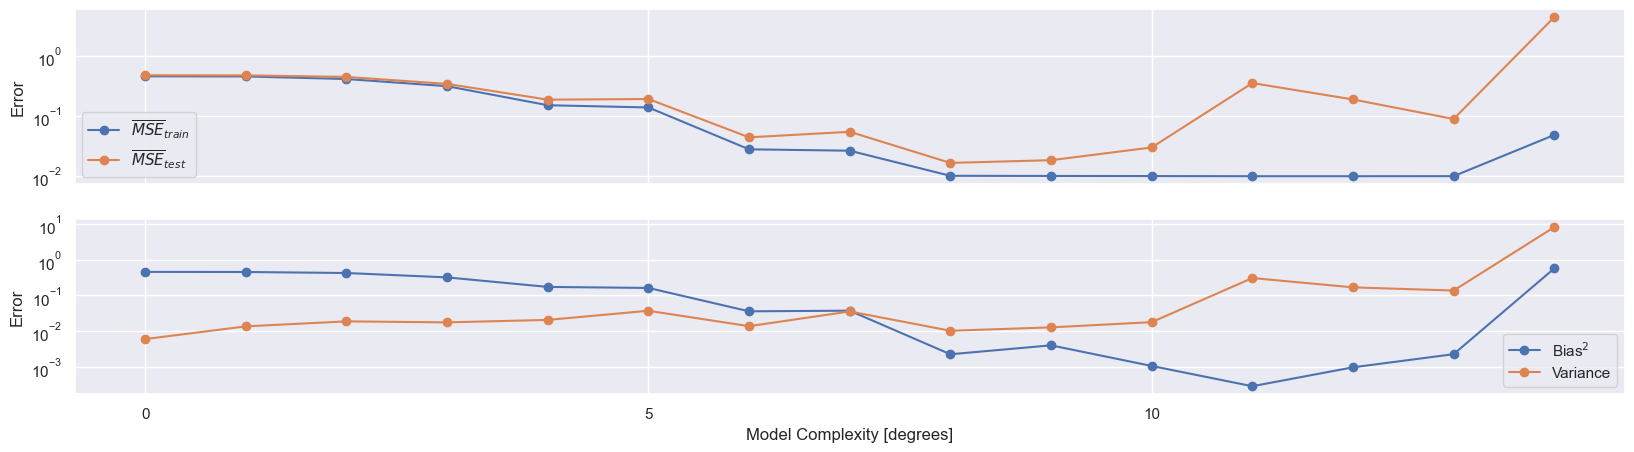

In [17]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(20, 5), sharex=True)
ax[0].plot(degrees, train_mses.mean(axis=1), "-o", label=r"$\overline{MSE}_{train}$")
ax[0].plot(degrees, test_mses.mean(axis=1), "-o", label=r"$\overline{MSE}_{test}$")
ax[0].set_xticks(degrees[::5], degrees[::5])
# ax[0].set_xlabel("Model Complexity [degrees]")
ax[0].set_ylabel("Error")
ax[0].legend()
ax[0].set_yscale("log")

ax[1].plot(degrees, bias2, "-o", label=r"Bias$^2$")
ax[1].plot(degrees, variance, "-o", label="Variance")
ax[1].set_xlabel("Model Complexity [degrees]")
ax[1].set_ylabel("Error")
ax[1].legend()
ax[1].set_yscale("log")

degree: 12
mse (train): 0.01
mse (test): 0.01
r2 (train): 0.98
r2 (test): 0.98


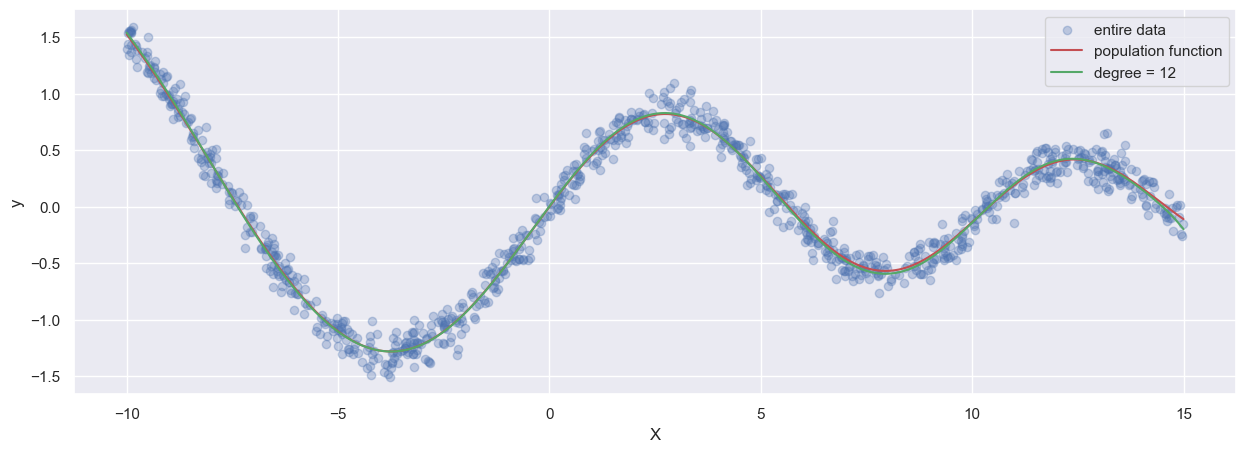

In [21]:
d = 12
X, y = df_pop[["X"]].values, df_pop[["y"]].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
w, b, mse_train, mse_test, r2_train, r2_test = do_poly_reg(X_train, X_test, y_train, y_test, d)
print(f"degree: {d}")
print(f"mse (train): {mse_train}")
print(f"mse (test): {mse_test}")
print(f"r2 (train): {r2_train}")
print(f"r2 (test): {r2_test}")

plt.figure(figsize=(15, 5))
plt.scatter(X, y, label="entire data", alpha=0.3)
plt.plot(x, population_fun_(x), "r", label="population function")
plt.plot(x, y_hat(x, w, b), color="g", label=f"degree = {d}")
plt.xlabel("X")
plt.ylabel("y")
plt.legend();